donnons toutes les informations sur le clients avant de lui contacter, quelle la probabilité que cette qualification va finir par une promesse de sa part ?

In [2]:
import sys

!{sys.executable} -m pip install xgboost

  Using cached xgboost-3.2.0-py3-none-win_amd64.whl.metadata (2.1 kB)
Using cached xgboost-3.2.0-py3-none-win_amd64.whl (101.7 MB)



[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay
)

from sklearn.inspection import permutation_importance
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

import time
import joblib

In [4]:
DATA_PATH = Path(r"C:\Users\rayan\Downloads\Datasets (1)\Datasets")

dataset = pd.read_csv(
    DATA_PATH / "final_dataset.csv"
)

print(dataset.shape)

dataset.head()

(13115, 43)


,id_qualification,id_client,date_qualification,type,statut,target,nom,prenom,specialite,adresse,...,debt_income_ratio,monthly_effort,financial_pressure,delay_category,credit_category,high_remaining_debt,high_debt_burden,specialisation,ville_gestionnaire,region_gestionnaire
0,3273,94,2025-09-12,SMS,Joignable,0,Rousseau,Madeleine,Chauffeur,"85 Boulevard Abdelmoumen, Oujda",...,13.145603,0.468056,7.691685,High,Good,1,1,Telephonique,Fès,Fès-Meknès
1,12310,294,2024-06-21,Deplacement,Joignable,0,Anderson,Monique,Fermier,"39 Boulevard Zerktouni, Tanger",...,5.263302,0.222820,3.453505,High,Very Low,1,1,Terrain,Tanger,Tanger-Tétouan-Al Hoceïma
2,878,28,2024-07-24,Deplacement,Joignable,0,Michel,Nicole,Consultant,"8 Rue Allal Ben Abdellah, Safi",...,0.476602,0.199278,0.031663,High,Very Low,0,0,Terrain,Marrakech,Marrakech-Safi
3,1490,29,2024-03-24,Deplacement,Joignable,0,Roux,Daniel,Comptable,"120 Boulevard Zerktouni, Safi",...,4.966769,0.440387,0.933602,High,Low,0,1,Terrain,Marrakech,Marrakech-Safi
4,2861,62,2025-12-18,Email,En cours,0,Garcia,Nathalie,Banquier,"110 Avenue des FAR, Meknès",...,4.816299,0.157661,2.452176,Medium,Good,1,1,Telephonique,Meknès,Fès-Meknès


Inspection du Dataset

In [5]:
print(dataset.info())

print()

print(dataset["target"].value_counts())

display(dataset.describe(include="all").T)

<class 'pandas.DataFrame'>
RangeIndex: 13115 entries, 0 to 13114
Data columns (total 43 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_qualification               13115 non-null  int64  
 1   id_client                      13115 non-null  int64  
 2   date_qualification             13115 non-null  str    
 3   type                           13115 non-null  str    
 4   statut                         13115 non-null  str    
 5   target                         13115 non-null  int64  
 6   nom                            13115 non-null  str    
 7   prenom                         13115 non-null  str    
 8   specialite                     13115 non-null  str    
 9   adresse                        13115 non-null  str    
 10  ville                          13115 non-null  str    
 11  region                         13115 non-null  str    
 12  id_gestionnaire                13115 non-null  int64  
 1

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id_qualification,13115.0,NaN,NaN,NaN,6558.0,3786.118725,1.0,3279.5,6558.0,9836.5,13115.0
id_client,13115.0,NaN,NaN,NaN,149.837286,89.382023,1.0,83.0,140.0,218.0,304.0
date_qualification,13115,731,2024-05-13,33,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,13115,4,Deplacement,5857,NaN,NaN,NaN,NaN,NaN,NaN,NaN
statut,13115,3,Joignable,5568,NaN,NaN,NaN,NaN,NaN,NaN,NaN
target,13115.0,NaN,NaN,NaN,0.051239,0.220493,0.0,0.0,0.0,0.0,1.0
nom,13115,40,David,802,NaN,NaN,NaN,NaN,NaN,NaN,NaN
prenom,13115,30,Marguerite,715,NaN,NaN,NaN,NaN,NaN,NaN,NaN
specialite,13115,24,Artisan,826,NaN,NaN,NaN,NaN,NaN,NaN,NaN
adresse,13115,303,"109 Avenue des FAR, Béni Mellal",119,NaN,NaN,NaN,NaN,NaN,NaN,NaN


suppression des identificateurs

In [6]:
identifier_columns = [

    "id_client",

    "id_qualification",

    "id_gestionnaire",

    "nom",

    "prenom",

    "adresse"

]

dataset = dataset.drop(

    columns=[

        c

        for c in identifier_columns

        if c in dataset.columns

    ]

)

dataset.head()

,date_qualification,type,statut,target,specialite,ville,region,nom_history,prenom_history,specialite_history,...,debt_income_ratio,monthly_effort,financial_pressure,delay_category,credit_category,high_remaining_debt,high_debt_burden,specialisation,ville_gestionnaire,region_gestionnaire
0,2025-09-12,SMS,Joignable,0,Chauffeur,Oujda,L'Oriental,Rousseau,Madeleine,Chauffeur,...,13.145603,0.468056,7.691685,High,Good,1,1,Telephonique,Fès,Fès-Meknès
1,2024-06-21,Deplacement,Joignable,0,Fermier,Tanger,Tanger-Tétouan-Al Hoceïma,Anderson,Monique,Fermier,...,5.263302,0.222820,3.453505,High,Very Low,1,1,Terrain,Tanger,Tanger-Tétouan-Al Hoceïma
2,2024-07-24,Deplacement,Joignable,0,Consultant,Safi,Marrakech-Safi,Michel,Nicole,Consultant,...,0.476602,0.199278,0.031663,High,Very Low,0,0,Terrain,Marrakech,Marrakech-Safi
3,2024-03-24,Deplacement,Joignable,0,Comptable,Safi,Marrakech-Safi,Roux,Daniel,Comptable,...,4.966769,0.440387,0.933602,High,Low,0,1,Terrain,Marrakech,Marrakech-Safi
4,2025-12-18,Email,En cours,0,Banquier,Meknès,Fès-Meknès,Garcia,Nathalie,Banquier,...,4.816299,0.157661,2.452176,Medium,Good,1,1,Telephonique,Meknès,Fès-Meknès


Separation des X et Y

In [7]:
X = dataset.drop(

    columns="target"

)

y = dataset["target"]

print(X.shape)

print(y.shape)

(13115, 36)
(13115,)


detection des types de features

In [8]:
categorical_features = X.select_dtypes(

    include=["object","category"]

).columns.tolist()

numerical_features = X.select_dtypes(

    include=np.number

).columns.tolist()

print("Categorical")

print(categorical_features)

print()

print("Numerical")

print(numerical_features)

Categorical
['date_qualification', 'type', 'statut', 'specialite', 'ville', 'region', 'nom_history', 'prenom_history', 'specialite_history', 'adresse_history', 'ville_history', 'region_history', 'delay_category', 'credit_category', 'specialisation', 'ville_gestionnaire', 'region_gestionnaire']

Numerical
['id_gestionnaire_history', 'previous_contacts', 'previous_promises', 'previous_promise_rate', 'had_previous_promise', 'average_days_between_contacts', 'days_since_previous_contact', 'montant_initial', 'montant_restant', 'revenu_mensuel', 'mensualite', 'jours_retard', 'score_credit', 'remaining_ratio', 'debt_income_ratio', 'monthly_effort', 'financial_pressure', 'high_remaining_debt', 'high_debt_burden']


C:\Users\rayan\AppData\Local\Temp\ipykernel_48580\3526025186.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


affichage des valeurs manquantes

In [9]:
display(

X.isna().sum()

.sort_values(

ascending=False

).head(20)

)

date_qualification               0
type                             0
statut                           0
specialite                       0
ville                            0
region                           0
nom_history                      0
prenom_history                   0
specialite_history               0
adresse_history                  0
ville_history                    0
region_history                   0
id_gestionnaire_history          0
previous_contacts                0
previous_promises                0
previous_promise_rate            0
had_previous_promise             0
average_days_between_contacts    0
days_since_previous_contact      0
montant_initial                  0
dtype: int64

L'importance des features

previous_contacts                0.211387
average_days_between_contacts    0.191522
previous_promise_rate            0.149239
days_since_previous_contact      0.140862
previous_promises                0.060080
score_credit                     0.022824
revenu_mensuel                   0.022498
remaining_ratio                  0.021480
montant_initial                  0.021279
monthly_effort                   0.021002
jours_retard                     0.020952
mensualite                       0.020937
financial_pressure               0.020304
debt_income_ratio                0.020029
montant_restant                  0.019609
id_gestionnaire_history          0.019586
had_previous_promise             0.011456
high_remaining_debt              0.002819
high_debt_burden                 0.002134
dtype: float64

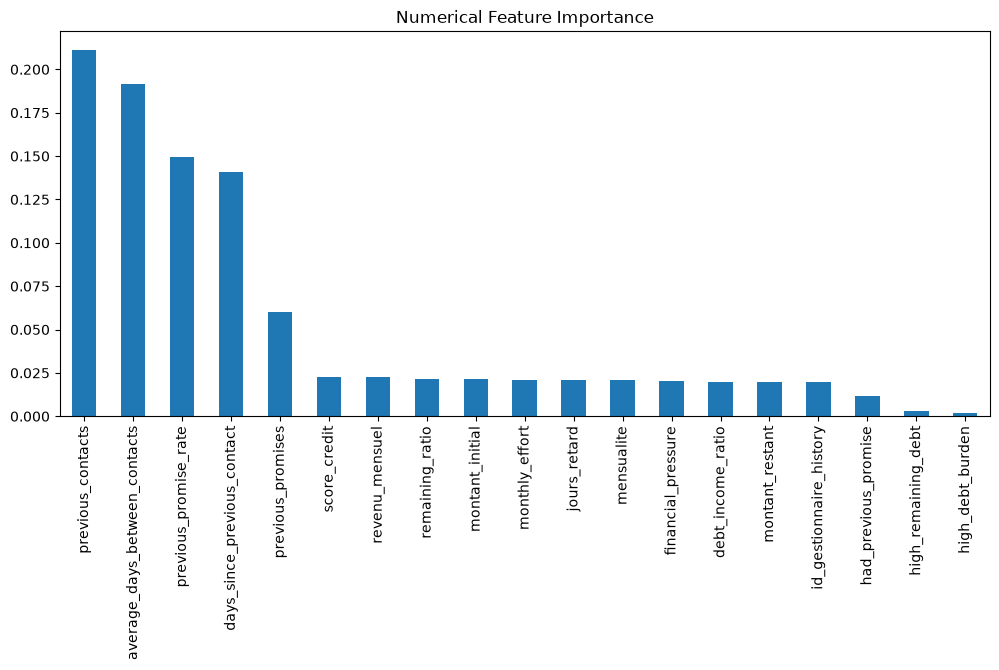

In [10]:
from sklearn.ensemble import RandomForestClassifier

X_num = X[numerical_features].fillna(0)

rf = RandomForestClassifier(

    n_estimators=300,

    random_state=42

)

rf.fit(

    X_num,

    y

)

importance = pd.Series(

    rf.feature_importances_,

    index=numerical_features

).sort_values(

    ascending=False

)

display(importance)

importance.plot(

    kind="bar",

    figsize=(12,5)

)

plt.title("Numerical Feature Importance")

plt.show()

matrice de correlation 

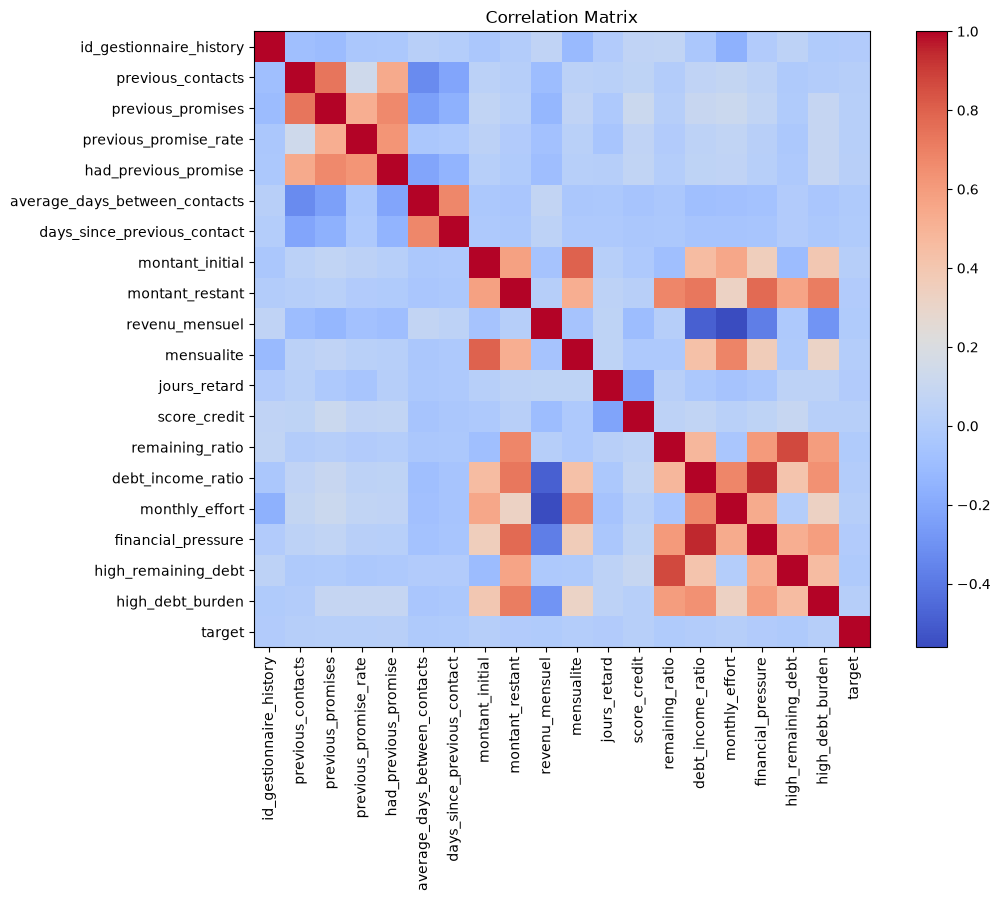

In [11]:
corr = dataset[numerical_features + ["target"]].corr()

plt.figure(figsize=(12,8))

plt.imshow(corr, cmap="coolwarm")

plt.colorbar()

plt.xticks(

    range(len(corr.columns)),

    corr.columns,

    rotation=90

)

plt.yticks(

    range(len(corr.columns)),

    corr.columns

)

plt.title("Correlation Matrix")

plt.show()

pipeline de preprocessing

In [12]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

train/test stratifié

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training set :", X_train.shape)
print("Testing set :", X_test.shape)

print("\nTrain target distribution")
print(y_train.value_counts(normalize=True))

print("\nTest target distribution")
print(y_test.value_counts(normalize=True))

Training set : (10492, 36)
Testing set : (2623, 36)

Train target distribution
target
0    0.948723
1    0.051277
Name: proportion, dtype: float64

Test target distribution
target
0    0.948913
1    0.051087
Name: proportion, dtype: float64


dummy baseline model 

In [14]:
from sklearn.dummy import DummyClassifier

dummy = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DummyClassifier(strategy="most_frequent"))
])

dummy.fit(X_train, y_train)

dummy_pred = dummy.predict(X_test)

print(classification_report(y_test, dummy_pred))

              precision    recall  f1-score   support

           0       0.95      1.00      0.97      2489
           1       0.00      0.00      0.00       134

    accuracy                           0.95      2623
   macro avg       0.47      0.50      0.49      2623
weighted avg       0.90      0.95      0.92      2623



c:\Users\rayan\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\rayan\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\rayan\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

In [15]:
import sys

print(sys.executable)

c:\Users\rayan\AppData\Local\Programs\Python\Python311\python.exe


In [16]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

print(scale_pos_weight)

18.50185873605948


definition de nos models :

In [17]:
models = {

    "Dummy": DummyClassifier(
        strategy="most_frequent"
    ),

    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=3000,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=500,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "SVM": SVC(
        probability=True,
        class_weight="balanced",
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        scale_pos_weight=scale_pos_weight,
        tree_method="hist",
        n_jobs=-1,
        random_state=42 
    )

}

fonction d'evaluation generique 

In [18]:
results = []

trained_models = {}

def evaluate_model(name, classifier):

    pipeline = Pipeline([

        ("preprocessor", preprocessor),

        ("classifier", classifier)

    ])

    start = time.time()

    pipeline.fit(
        X_train,
        y_train
    )

    training_time = time.time() - start

    prediction = pipeline.predict(
        X_test
    )

    probability = None

    if hasattr(
        pipeline,
        "predict_proba"
    ):

        probability = pipeline.predict_proba(
            X_test
        )[:,1]

    trained_models[name] = pipeline

    metrics = {

        "Model":name,

        "Accuracy":accuracy_score(
            y_test,
            prediction
        ),

        "Precision":precision_score(
            y_test,
            prediction,
            zero_division=0
        ),

        "Recall":recall_score(
            y_test,
            prediction,
            zero_division=0
        ),

        "F1":f1_score(
            y_test,
            prediction,
            zero_division=0
        ),

        "ROC-AUC":
        roc_auc_score(
            y_test,
            probability
        ) if probability is not None else np.nan,

        "Training Time (s)":training_time

    }

    results.append(metrics)

    print("="*70)
    print(name)
    print("="*70)

    print(
        classification_report(
            y_test,
            prediction,
            zero_division=0
        )
    )

    return pipeline

entrainement de chaque modèle

In [19]:
for name, model in models.items():

    evaluate_model(
        name,
        model
    )

Dummy
              precision    recall  f1-score   support

           0       0.95      1.00      0.97      2489
           1       0.00      0.00      0.00       134

    accuracy                           0.95      2623
   macro avg       0.47      0.50      0.49      2623
weighted avg       0.90      0.95      0.92      2623



c:\Users\rayan\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 3000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=3000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression
              precision    recall  f1-score   support

           0       0.98      0.69      0.81      2489
           1       0.11      0.72      0.19       134

    accuracy                           0.69      2623
   macro avg       0.55      0.71      0.50      2623
weighted avg       0.93      0.69      0.78      2623

KNN
              precision    recall  f1-score   support

           0       0.95      1.00      0.97      2489
           1       1.00      0.01      0.01       134

    accuracy                           0.95      2623
   macro avg       0.97      0.50      0.49      2623
weighted avg       0.95      0.95      0.92      2623

Decision Tree
              precision    recall  f1-score   support

           0       0.96      0.92      0.94      2489
           1       0.13      0.23      0.17       134

    accuracy                           0.88      2623
   macro avg       0.54      0.57      0.55      2623
weighted avg       0.91      0.88   

c:\Users\rayan\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM
              precision    recall  f1-score   support

           0       0.95      0.47      0.63      2489
           1       0.06      0.58      0.10       134

    accuracy                           0.48      2623
   macro avg       0.51      0.53      0.37      2623
weighted avg       0.91      0.48      0.61      2623

XGBoost
              precision    recall  f1-score   support

           0       0.97      0.77      0.86      2489
           1       0.12      0.58      0.20       134

    accuracy                           0.76      2623
   macro avg       0.55      0.68      0.53      2623
weighted avg       0.93      0.76      0.83      2623



In [21]:
comparison = (

    pd.DataFrame(results)

    .sort_values(

        by="F1",

        ascending=False

    )

    .reset_index(drop=True)

)

display(comparison)

comparison.style.background_gradient(
    cmap="Greens"
)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Training Time (s)
0,XGBoost,0.761342,0.120370,0.582090,0.199488,0.802122,1.815001
1,Logistic Regression,0.691956,0.111751,0.723881,0.193613,0.752109,7.543280
2,Decision Tree,0.882958,0.131915,0.231343,0.168022,0.574691,1.565182
3,SVM,0.478460,0.056115,0.582090,0.102362,0.521255,147.699277
4,Random Forest,0.919558,0.036145,0.022388,0.027650,0.773659,8.124401
5,KNN,0.949295,1.000000,0.007463,0.014815,0.505911,0.367544
6,Dummy,0.948913,0.000000,0.000000,0.000000,0.500000,0.456095


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Training Time (s)
0,XGBoost,0.761342,0.120370,0.582090,0.199488,0.802122,1.815001
1,Logistic Regression,0.691956,0.111751,0.723881,0.193613,0.752109,7.543280
2,Decision Tree,0.882958,0.131915,0.231343,0.168022,0.574691,1.565182
3,SVM,0.478460,0.056115,0.582090,0.102362,0.521255,147.699277
4,Random Forest,0.919558,0.036145,0.022388,0.027650,0.773659,8.124401
5,KNN,0.949295,1.000000,0.007463,0.014815,0.505911,0.367544
6,Dummy,0.948913,0.000000,0.000000,0.000000,0.500000,0.456095
